In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset("titanic")
print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)
print("\nColumn names:")
print(df.columns.tolist())

for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique()[:15])

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

survived:
[0 1]

pclass:
[3 1 2]

sex:
<ArrowStringArray>
['male', 'female']
Length: 2, dtype: str

age:
[22. 38. 26. 35. nan 54.  2. 27. 14.  4. 58. 20. 39. 55. 31.]

sibsp:
[1 0 3 4 2 5 8]

parch:
[0 1 2 5 3 4 6]

fare:
[ 7.25   71.2833  7.925  53.1     8.05    8.4583 51.8625 21.075  11.1333
 30.0708 16.7    26.55   31.275   7.8542 16.    ]

embarked:
<ArrowStringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

class:
['Third', 'First', 'Second']
Categories (3, str): ['First', 'Second', 'Third']

who:
<ArrowStringArray>
['man', 'woman', 'child']
Length: 3, dtype: str

adult_male:
[ True False]

deck:
[NaN, 'C', 'E', 'G', 'D', 'A', 'B', 'F']
Categories (7, str): ['A', 'B', 'C', 'D', 'E', 'F', 'G']

embark_town:
<ArrowStringArray>
['Southampton', 'Cherbourg', 'Queenstown', nan]
Length: 4, dtype: str

alive:
<ArrowStringArray

In [4]:
print("Duplicate rows before cleaning:", df.duplicated().sum())
print("Shape before removing duplicates:", df.shape)

Duplicate rows before cleaning: 107
Shape before removing duplicates: (891, 15)


In [5]:
missing = df.isnull().sum()
print("Missing values before cleaning:")
print(missing[missing > 0].sort_values(ascending=False))

Missing values before cleaning:
deck           688
age            177
embarked         2
embark_town      2
dtype: int64


In [6]:
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "str", "category", "bool"]).columns:
    if df[col].isnull().any():
        modes = df[col].mode()
        if not modes.empty:
            df[col] = df[col].fillna(modes.iloc[0])
print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


In [7]:
print("Duplicates after missing-value handling:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Duplicates after removal:", df.duplicated().sum())

Duplicates after missing-value handling: 112
Duplicates after removal: 0


In [8]:
features = ["pclass","age","sibsp","parch","fare","sex","embarked","alone"]
X = df[features].copy()
y = df["survived"].copy()
print("Selected features:")
display(X.head())
print("\nTarget variable:")
display(y.head())
print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Selected features:


,pclass,age,sibsp,parch,fare,sex,embarked,alone
0,3,22.0,1,0,7.2500,male,S,False
1,1,38.0,1,0,71.2833,female,C,False
2,3,26.0,0,0,7.9250,female,S,True
3,1,35.0,1,0,53.1000,female,S,False
4,3,35.0,0,0,8.0500,male,S,True



Target variable:


0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


Feature shape: (779, 8)
Target shape: (779,)


In [9]:
categorical_cols = X.select_dtypes(include=["object", "str", "category", "bool"]).columns.tolist()
X_encoded = pd.get_dummies(X,columns=categorical_cols,dtype=int)
print("Encoded dataset:")
display(X_encoded.head())
print("Shape after encoding:", X_encoded.shape)

Encoded dataset:


,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,alone_False,alone_True
0,3,22.0,1,0,7.2500,0,1,0,0,1,1,0
1,1,38.0,1,0,71.2833,1,0,1,0,0,1,0
2,3,26.0,0,0,7.9250,1,0,0,0,1,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1,1,0
4,3,35.0,0,0,8.0500,0,1,0,0,1,0,1


Shape after encoding: (779, 12)


In [10]:
numeric_cols = X_encoded.select_dtypes(include="number").columns.tolist()
X_normalized = X_encoded.copy()
for col in numeric_cols:
    min_val = X_normalized[col].min()
    max_val = X_normalized[col].max()
    if max_val != min_val:
        X_normalized[col]=((X_normalized[col] - min_val) /(max_val - min_val))

print("Normalized dataset:")
display(X_normalized.head())

Normalized dataset:


,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,alone_False,alone_True
0,1.0,0.271174,0.125,0.0,0.014151,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1,0.0,0.472229,0.125,0.0,0.139136,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,1.0,0.321438,0.000,0.0,0.015469,1.0,0.0,0.0,0.0,1.0,0.0,1.0
3,0.0,0.434531,0.125,0.0,0.103644,1.0,0.0,0.0,0.0,1.0,1.0,0.0
4,1.0,0.434531,0.000,0.0,0.015713,0.0,1.0,0.0,0.0,1.0,0.0,1.0


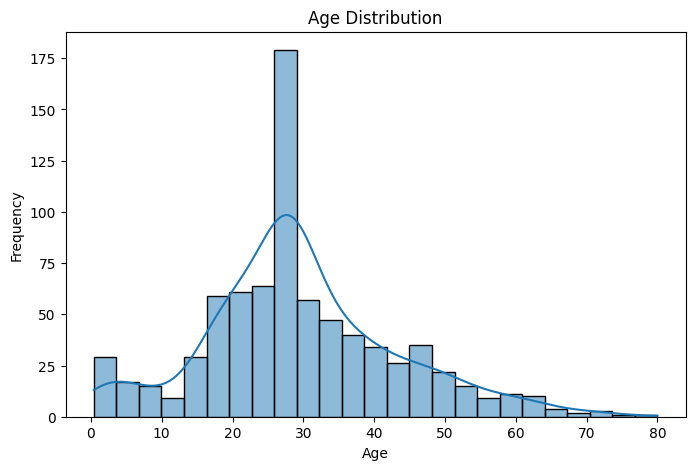

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df["age"], bins=25, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

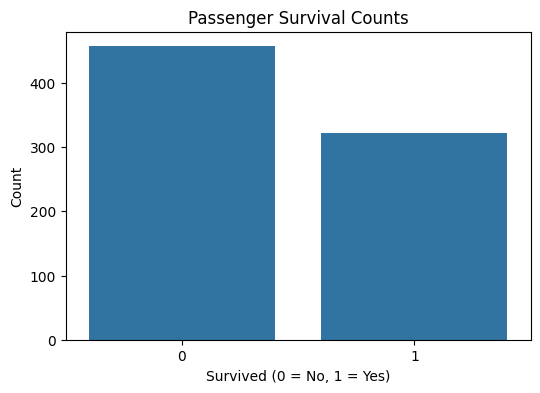

In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="survived")
plt.title("Passenger Survival Counts")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

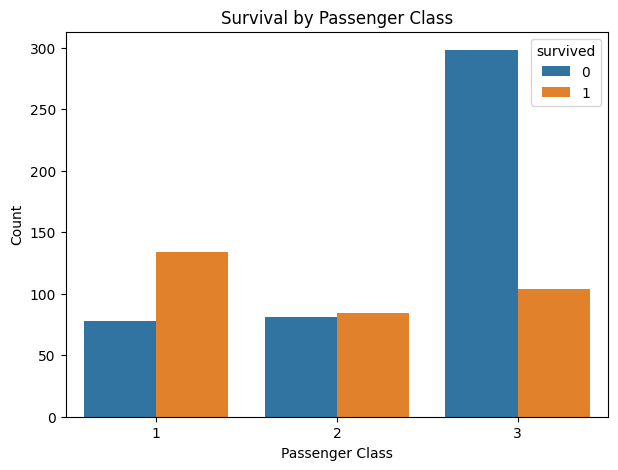

In [13]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="pclass", hue="survived")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

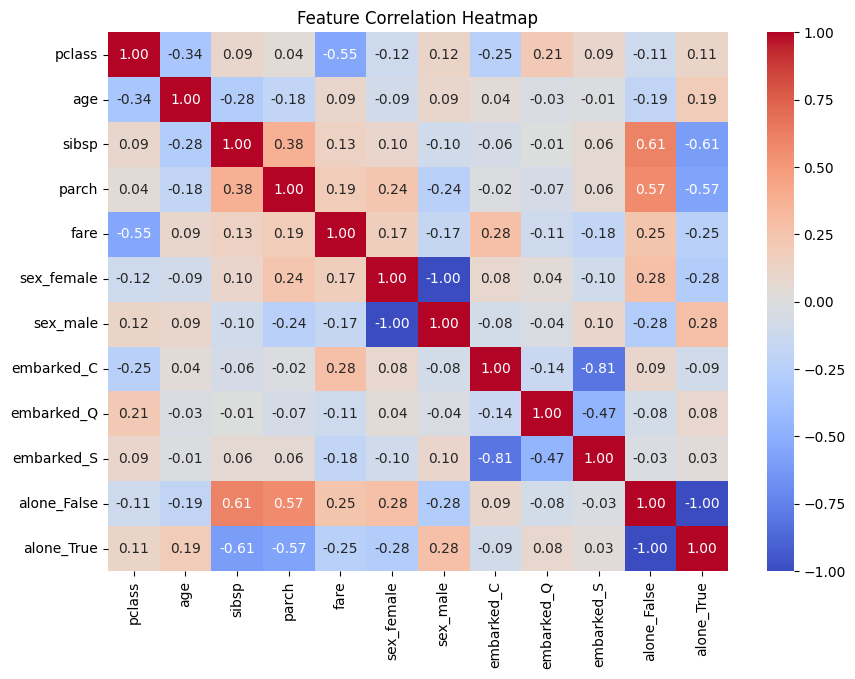

In [14]:
plt.figure(figsize=(10, 7))
sns.heatmap(X_encoded.select_dtypes(include="number").corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [15]:
print("Missing values remaining:", df.isnull().sum().sum())
print("Duplicate rows remaining:", df.duplicated().sum())
df.to_csv("titanic_cleaned.csv", index=False)
X_normalized.to_csv("titanic_preprocessed_features.csv", index=False)
y.to_csv("titanic_target.csv", index=False)
print("All datasets saved successfully!")

Missing values remaining: 0
Duplicate rows remaining: 0
All datasets saved successfully!
